First, I read in the data files

In [29]:
# Data libraries

import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
from matplotlib import image as mpimg
import seaborn as sns

# sklearn modules
import sklearn

df_avg = pd.read_csv("csv_files/avg_river_levels.csv")
df_min = pd.read_csv("csv_files/min_river_levels.csv")
df_max = pd.read_csv("csv_files/max_river_levels.csv")
df_locs = pd.read_csv("csv_files/monitoring_locations.csv")



Then I plotted a map showing the locations of the stations, then overlayed this on a map of Scotland using https://kepler.gl/demo? 


then we investigated missing values in the data.we plotted  timeseries to investigate how missing data changes over time, and found that the vast majority of data was missing until ??? 2018, so we cleaned the data by getting rid of ??? imputing ???? idk guys fill this in  xxxxx then i plotted a histogram to see how many stations were missing certain amounts of data, and then created a heatmap to show if the stations with lots of missing data happened to be concentrated in a certain area. Then i coloured the map of scotland by the amount of missing data to see if this made a difference. 

NOTE will need to redo this and create heatmap and histogram again once we have a new dataset. 

In [46]:
# This code chunk filters the data

# Stations outside Scotland
# Remove all observation IDs associated with these stations
stations_to_remove = df_locs.loc[
    df_locs["Station_Name"].str.strip().str.lower().isin(
        ["portrush", "bangor", "port erin"]
    ),
    "Observation_ID"
].tolist()


# ===============
# DF AVERAGE
# ===============

# Work with data in wide form
df_avg = df_avg.replace(999999.999, np.nan)

dates1 = pd.to_datetime(df_avg.columns[3:], dayfirst=True)
vals1 = df_avg.iloc[:, 3:].copy()
vals1.columns = dates1
vals1.index = df_avg["Observation_ID"]
vals1 = vals1.T

# Full daily data with NA rows where gaps were
vals1 = vals1.reindex(pd.date_range(vals1.index.min(), vals1.index.max(), freq="D"))

# Drop stations outside Scotland
vals1 = vals1.drop(columns=stations_to_remove, errors="ignore")

# Drop big station-wide outage DAYS
good1 = vals1[vals1.isna().mean(axis=1) <= 0.5]

# Drop STATIONS missing more than 10% of remaining data
miss1 = good1.isna().mean()
keep1 = miss1.index[miss1 <= 0.1]
filtered_avg = good1[keep1]


# ===============
# DF MIN
# ===============

df_min = df_min.replace(999999.999, np.nan)

dates2 = pd.to_datetime(df_min.columns[3:], dayfirst=True)
vals2 = df_min.iloc[:, 3:].copy()
vals2.columns = dates2
vals2.index = df_min["Observation_ID"]
vals2 = vals2.T

# Full daily data with NA rows where gaps were
vals2 = vals2.reindex(pd.date_range(vals2.index.min(), vals2.index.max(), freq="D"))

# Drop stations outside Scotland
vals2 = vals2.drop(columns=stations_to_remove, errors="ignore")

# Drop big station-wide outage DAYS
good2 = vals2[vals2.isna().mean(axis=1) <= 0.5]

# Drop STATIONS missing more than 10% of remaining data
miss2 = good2.isna().mean()
keep2 = miss2.index[miss2 <= 0.1]
filtered_min = good2[keep2]


# ===============
# DF MAX
# ===============

df_max = df_max.replace(999999.999, np.nan)

dates3 = pd.to_datetime(df_max.columns[3:], dayfirst=True)
vals3 = df_max.iloc[:, 3:].copy()  # Fixed: previously used df_min
vals3.columns = dates3
vals3.index = df_max["Observation_ID"]
vals3 = vals3.T

# Full daily data with NA rows where gaps were
vals3 = vals3.reindex(pd.date_range(vals3.index.min(), vals3.index.max(), freq="D"))

# Drop stations outside Scotland
vals3 = vals3.drop(columns=stations_to_remove, errors="ignore")

# Drop big station-wide outage DAYS
good3 = vals3[vals3.isna().mean(axis=1) <= 0.5]

# Drop STATIONS missing more than 10% of remaining data
miss3 = good3.isna().mean()
keep3 = miss3.index[miss3 <= 0.1]
filtered_max = good3[keep3]


# filter the locations 

# Keep stations present in all three filtered datasets
common_stations = (
    filtered_avg.columns
    .intersection(filtered_min.columns)
    .intersection(filtered_max.columns)
)

df_locs_filtered = df_locs[
    df_locs["Observation_ID"].isin(common_stations)
].copy()

print("Original stations:", len(df_locs))
print("Filtered stations:", len(df_locs_filtered))


Original stations: 392
Filtered stations: 323


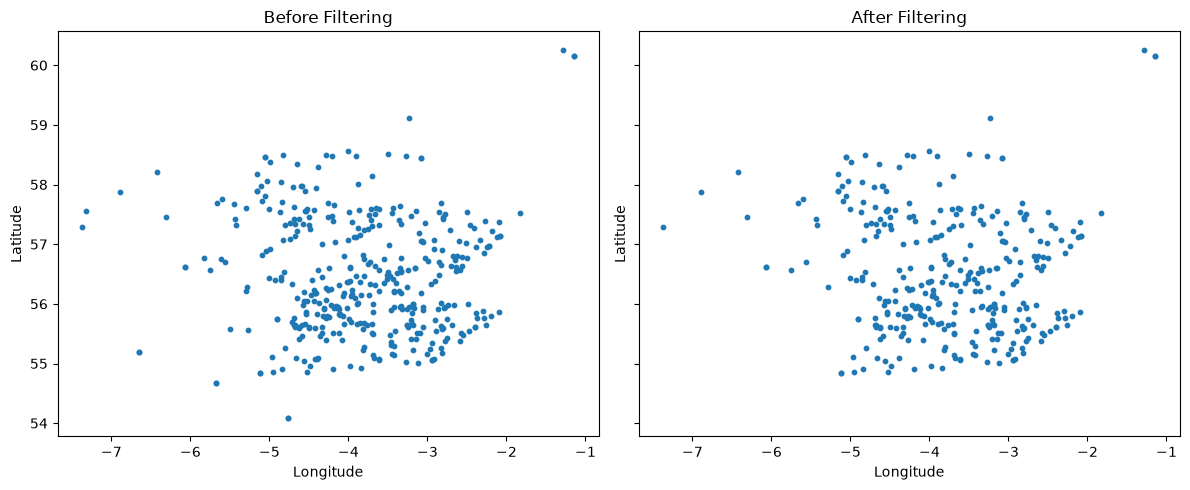

In [47]:
#Locations of stations
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

ax[0].scatter(df_locs["Longitude"], df_locs["Latitude"], s=10)
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")
ax[0].set_title("Before Filtering")

ax[1].scatter(df_locs_filtered["Longitude"], df_locs_filtered["Latitude"], s=10)
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
ax[1].set_title("After Filtering")

plt.tight_layout()
plt.show()


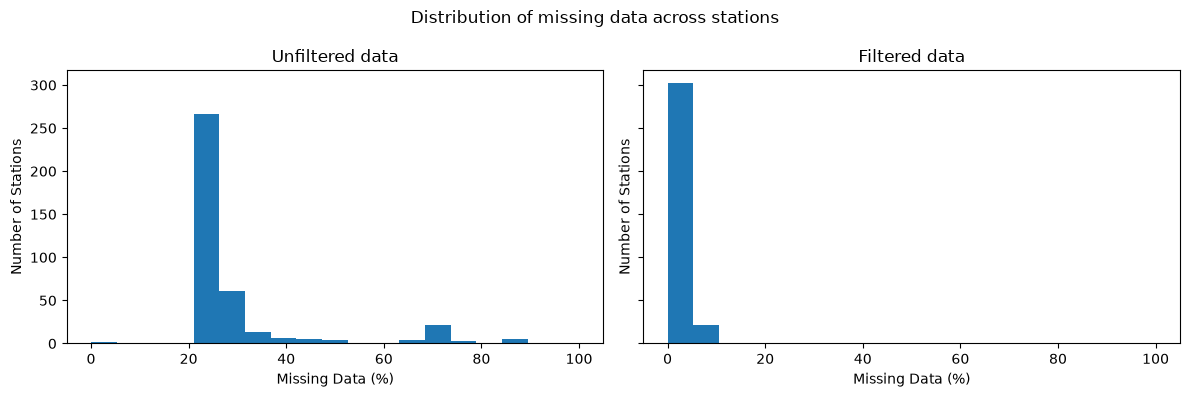

Unfiltered stations with no missing data: 0
Filtered stations with no missing data: 68


In [48]:
#Histograms of missing data across stations 
# Unfiltered
miss_unfil = df_avg.iloc[:, 3:].isna().mean(axis=1) * 100

# Filtered
miss_fil = filtered_avg.isna().mean(axis=0) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True, sharex=True)
bins = np.linspace(0, 100, 20)

ax[0].hist(miss_unfil, bins=bins)
ax[0].set_xlabel("Missing Data (%)")
ax[0].set_ylabel("Number of Stations")
ax[0].set_title("Unfiltered data")

ax[1].hist(miss_fil, bins=bins)
ax[1].set_xlabel("Missing Data (%)")
ax[1].set_ylabel("Number of Stations")
ax[1].set_title("Filtered data")

plt.suptitle("Distribution of missing data across stations")
plt.tight_layout()
plt.show()

#how many are missing per station
print("Unfiltered stations with no missing data:", (miss_unfil == 0).sum())
print("Filtered stations with no missing data:", (miss_fil == 0).sum())

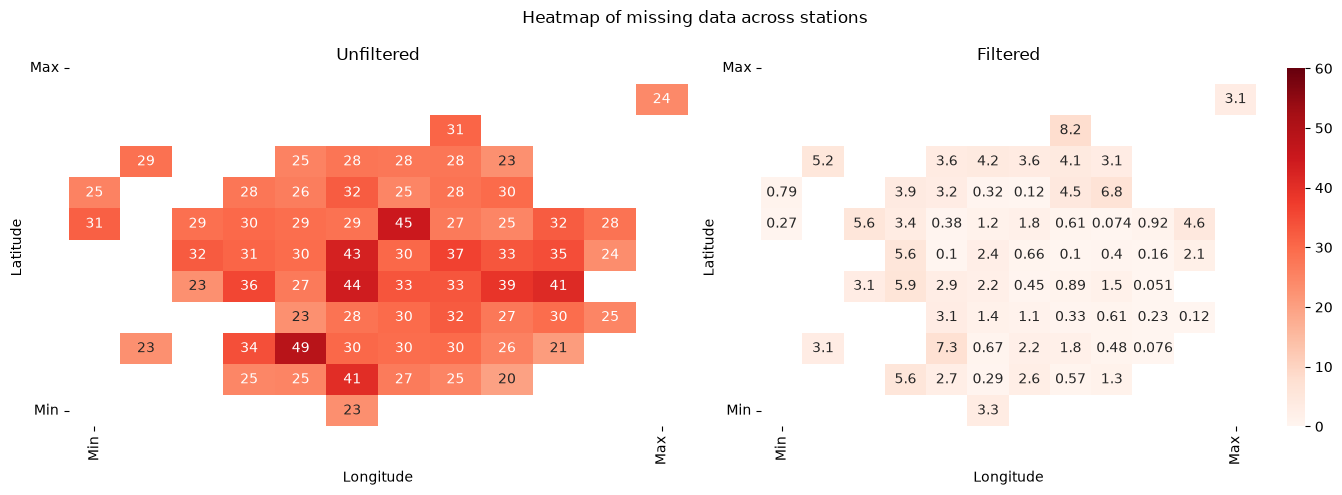

In [22]:
#Heatmap of missing stations 
# Unfiltered
df_map_unfil = df_locs.set_index("Observation_ID").copy()
df_map_unfil["Missing"] = miss_unfil.set_axis(df_avg["Observation_ID"]).reindex(df_map_unfil.index)

# Filtered
df_map_fil = df_locs.set_index("Observation_ID").copy()
df_map_fil["Missing"] = miss_fil.reindex(df_map_fil.index)
df_map_fil = df_map_fil.loc[df_map_fil.index.intersection(miss_fil.index)]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for i, df_map in enumerate([df_map_unfil, df_map_fil]):
    df_map = df_map.copy()

    df_map["Latitude"] = pd.cut(df_map["Latitude"], bins=12)
    df_map["Longitude"] = pd.cut(df_map["Longitude"], bins=12)

    heatmap_data = df_map.pivot_table(
        values="Missing",
        index="Latitude",
        columns="Longitude",
        observed=False
    )

    sns.heatmap(heatmap_data, annot=True, cmap="Reds",
                vmin=0, vmax=60, ax=ax[i], cbar=(i == 1))

    ax[i].set_title(["Unfiltered", "Filtered"][i])
    ax[i].set_xticks([0.5, 11.5])
    ax[i].set_xticklabels(["Min", "Max"])
    ax[i].set_yticks([0.5, 11.5])
    ax[i].set_yticklabels(["Min", "Max"])
    ax[i].invert_yaxis()

plt.suptitle("Heatmap of missing data across stations")
plt.tight_layout()
plt.show()

In [49]:
# Water level data only - using the filtered datasets
avg = filtered_avg.T.copy()
min_level = filtered_min.T.copy()
max_level = filtered_max.T.copy()

# Make sure all three datasets contain the same stations and dates
common_stations = avg.index.intersection(min_level.index).intersection(max_level.index)
common_dates = avg.columns.intersection(min_level.columns).intersection(max_level.columns)

#Make sure order is correct 
avg = avg.sort_index(axis=1)
avg = avg.loc[common_stations, common_dates]
min_level = min_level.sort_index(axis=1)
min_level = min_level.loc[common_stations, common_dates]
max_level = max_level.sort_index(axis=1)
max_level = max_level.loc[common_stations, common_dates]

#Calculate metrics used to get features 
daily_range = max_level - min_level
daily_change = avg.T.asfreq("D").diff().T

# Create new dataset using the stations remaining after filtering
df_features = df_locs.set_index("Observation_ID").loc[common_stations].copy()

# Calculating the daily range and the change between days
daily_range = max_level - min_level

# Calculate changes only between consecutive calendar days
daily_change = avg.T.asfreq("D").diff().T

# Calculating all of the features
df_features["Std_Level"] = avg.std(axis=1)
df_features["Mean_Daily_Range"] = daily_range.mean(axis=1)
df_features["Std_Daily_Range"] = daily_range.std(axis=1)
df_features["Mean_Absolute_Daily_Change"] = daily_change.abs().mean(axis=1)
df_features["Std_Daily_Change"] = daily_change.std(axis=1)
df_features["90th_Daily_Range"] = daily_range.quantile(0.90, axis=1)

# Percent of days in each station with a range above the 90th percentile
# https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.gt.html
threshold_range = daily_range.stack().quantile(0.90)
df_features["Percent_Range_Above_90th"] = (
    daily_range.gt(threshold_range).sum(axis=1)
    / daily_range.notna().sum(axis=1) * 100
)

# Percent of days in each station with a water level rise greater above the 90th percentile
threshold_rise = daily_change.stack().quantile(0.90)
df_features["Percent_Rise_Above_90th"] = (
    daily_change.gt(threshold_rise).sum(axis=1)
    / daily_change.notna().sum(axis=1) * 100
)

df_features = df_features.reset_index()
df_features.to_csv("df_features.csv", index=False)
